# Supplementary figures

SI figures of the paper-style set, regenerated from the saved results of `OUT`:

| file | figure |
|---|---|
| `figures/paper/figS_parity_stages` | parity of LI fluxes and metabolites for the literature model, the initial estimation (37 free), the final model and LOOCV |
| `figures/paper/figS_parameter_evolution` | all 37 parameter values across the stages; fixed parameters show the rule that fixed them |
| `figures/paper/figS_bootstrap_all` | bootstrap distributions of the free parameters with the estimate and the BC 95% interval |
| `figures/paper/figS_profiles_all` | re-optimised profile likelihoods of the free parameters with the 95% threshold |

Each figure is written out in full in its own cell; the panels of the multi-panel figures are written one by one. The parity and evolution figures work for any structure; the two figures with one panel per free parameter are laid out for **11 free parameters** (a 3 x 4 grid whose last cell holds the legend). If a run ends with a different number of free parameters, the check cell stops with a message and the panels have to be added or removed. Needs the outputs of `parameter_selection`, `final_fit`, `bootstrap`, `profiles`, `loocv` and `figure_data` (run order in `notebooks/README.md`).

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import paper_style as S
from model.parameters import ALL_PARAMS, LI_FLUX_KEYS
from data import measured_balanced_keys
from settings import THRESHOLDS

PAPER = os.path.join(OUT, "figures", "paper")
DATA = os.path.join(OUT, "paper_figs_data")
if WRITABLE:
    os.makedirs(PAPER, exist_ok=True)

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : False (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


In [2]:
needed = {
    "stage0/theta_full.csv": "parameter_selection", "stage0/pred_insample_predicted.csv": "parameter_selection",
    "reduction/fixing_log.csv": "parameter_selection", "final/final_structure.csv": "final_fit", "final/theta_full.csv": "final_fit",
    "final/pred_insample_predicted.csv": "final_fit", "final/pred_insample_real.csv": "final_fit",
    "bootstrap/bootstrap_theta.csv": "bootstrap", "profiles/profiles_all.csv": "profiles", "profiles/profile_summary.csv": "profiles",
    "profiles/profile_thresholds.json": "profiles", "loocv/loocv_pred.csv": "loocv",
    "paper_figs_data/stage_metrics.csv": "figure_data (after loocv)", "paper_figs_data/y_literature_inner.csv": "figure_data (HK_RUN=1)",
}
absent = {f: step for f, step in needed.items() if not os.path.exists(os.path.join(OUT, f))}
if absent:
    raise FileNotFoundError("missing results of earlier steps (run them first):\n" + "\n".join("  %-45s written by %s" % (f, s) for f, s in absent.items()))

def path(*parts):
    return os.path.join(OUT, *parts)

final_structure = pd.read_csv(path("final", "final_structure.csv"))
profile_summary = pd.read_csv(path("profiles", "profile_summary.csv"), index_col=0)
FREE = [p for p in ALL_PARAMS if p in set(final_structure.loc[final_structure["status"] == "free", "param"])]
CLASS_OF = S.classes_of_free(final_structure, profile_summary)
literature = pd.read_csv(os.path.join(REPO, "Data", "theta_init_sampled.csv"), index_col=0)["value"]
th0 = pd.read_csv(path("stage0", "theta_full.csv"), index_col=0)["value"]
thf = pd.read_csv(path("final", "theta_full.csv"), index_col=0)["value"]
stage_metrics = pd.read_csv(path("paper_figs_data", "stage_metrics.csv"), index_col=0)
print("free (%d): %s" % (len(FREE), FREE))

free (11): ['K_g6p_1', 'Ks_g6p_pgi', 'kcat_f_2', 'kcat_f_3', 'Ks_fbp_4', 'kcat_f_4', 'kcat_f_5', 'kcat_f_6', 'kcat_f_7', 'kcat_f_8', 'kcat_f_9']


## Fig. S6: parity for every stage

Top row: the 5 LI fluxes, bottom row: the 6 measured metabolites (log-log). Columns: literature model (37 fixed), initial estimation (37 free), final model, LOOCV held-out predictions. RMSE and $R^2$ (against the per-output mean) from `stage_metrics.csv`.

In [3]:
real = pd.read_csv(path("final", "pred_insample_real.csv"), index_col=0)
pred = {
    "literature": pd.read_csv(path("paper_figs_data", "y_literature_inner.csv"), index_col=0),
    "stage0": pd.read_csv(path("stage0", "pred_insample_predicted.csv"), index_col=0),
    "final": pd.read_csv(path("final", "pred_insample_predicted.csv"), index_col=0),
    "loocv": pd.read_csv(path("loocv", "loocv_pred.csv"), index_col=0),
}
pred = {k: v.reindex(index=real.index, columns=real.columns) for k, v in pred.items()}
m = stage_metrics
met_cols = measured_balanced_keys()

def pairs(df, cols):
    yr = real[cols].to_numpy(float).ravel()
    yp = df[cols].to_numpy(float).ravel()
    ok = np.isfinite(yr) & np.isfinite(yp)
    return yp[ok], yr[ok]

f_lit = pairs(pred["literature"], LI_FLUX_KEYS)
f_0 = pairs(pred["stage0"], LI_FLUX_KEYS)
f_f = pairs(pred["final"], LI_FLUX_KEYS)
f_l = pairs(pred["loocv"], LI_FLUX_KEYS)
c_lit = pairs(pred["literature"], met_cols)
c_0 = pairs(pred["stage0"], met_cols)
c_f = pairs(pred["final"], met_cols)
c_l = pairs(pred["loocv"], met_cols)
FMAX = 8.5
CLO, CHI = 3e-3, 3.0

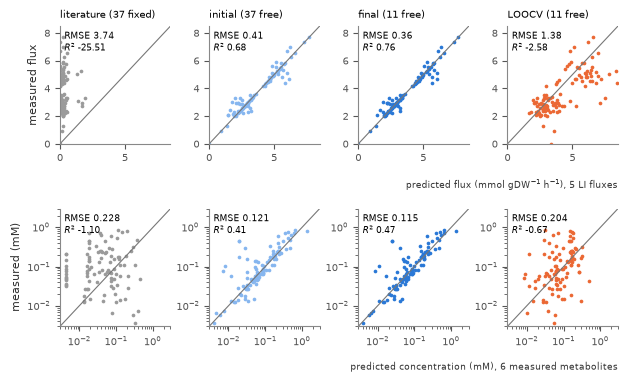

In [4]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.9))
plt.subplots_adjust(wspace=0.35, hspace=0.55)
ax_f1, ax_f2, ax_f3, ax_f4 = axes[0]
ax_c1, ax_c2, ax_c3, ax_c4 = axes[1]

# ---- fluxes ----
ax_f1.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f1.scatter(f_lit[0], f_lit[1], s=7, color=S.STAGE_COLOR["literature"], lw=0)
ax_f1.set_xlim(0, FMAX)
ax_f1.set_ylim(0, FMAX)
ax_f1.set_title("literature (37 fixed)", fontsize=7.5)
ax_f1.text(0.04, 0.96, "RMSE %.2f\n$R^2$ %.2f" % (m.loc["literature", "rmse_flux_li"], m.loc["literature", "r2_flux_li_permean"]), transform=ax_f1.transAxes, va="top", fontsize=6.2)
ax_f1.set_ylabel("measured flux")

ax_f2.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f2.scatter(f_0[0], f_0[1], s=7, color=S.STAGE_COLOR["stage0"], lw=0)
ax_f2.set_xlim(0, FMAX)
ax_f2.set_ylim(0, FMAX)
ax_f2.set_title("initial (37 free)", fontsize=7.5)
ax_f2.text(0.04, 0.96, "RMSE %.2f\n$R^2$ %.2f" % (m.loc["stage0", "rmse_flux_li"], m.loc["stage0", "r2_flux_li_permean"]), transform=ax_f2.transAxes, va="top", fontsize=6.2)

ax_f3.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f3.scatter(f_f[0], f_f[1], s=7, color=S.STAGE_COLOR["final"], lw=0)
ax_f3.set_xlim(0, FMAX)
ax_f3.set_ylim(0, FMAX)
ax_f3.set_title("final (%d free)" % len(FREE), fontsize=7.5)
ax_f3.text(0.04, 0.96, "RMSE %.2f\n$R^2$ %.2f" % (m.loc["final", "rmse_flux_li"], m.loc["final", "r2_flux_li_permean"]), transform=ax_f3.transAxes, va="top", fontsize=6.2)

ax_f4.plot([0, FMAX], [0, FMAX], color=S.MUTED, lw=0.8)
ax_f4.scatter(f_l[0], f_l[1], s=7, color=S.STAGE_COLOR["loocv"], lw=0)
ax_f4.set_xlim(0, FMAX)
ax_f4.set_ylim(0, FMAX)
ax_f4.set_title("LOOCV (%d free)" % len(FREE), fontsize=7.5)
ax_f4.text(0.04, 0.96, "RMSE %.2f\n$R^2$ %.2f" % (m.loc["loocv", "rmse_flux_li"], m.loc["loocv", "r2_flux_li_permean"]), transform=ax_f4.transAxes, va="top", fontsize=6.2)
ax_f4.text(1.0, -0.3, "predicted flux (mmol gDW$^{-1}$ h$^{-1}$), 5 LI fluxes", transform=ax_f4.transAxes, ha="right", va="top", fontsize=6.8, color=S.INK)

# ---- metabolites ----
ax_c1.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c1.scatter(c_lit[0], c_lit[1], s=7, color=S.STAGE_COLOR["literature"], lw=0)
ax_c1.set_xscale("log")
ax_c1.set_yscale("log")
ax_c1.set_xlim(CLO, CHI)
ax_c1.set_ylim(CLO, CHI)
ax_c1.text(0.04, 0.96, "RMSE %.3f\n$R^2$ %.2f" % (m.loc["literature", "rmse_met"], m.loc["literature", "r2_met_permean"]), transform=ax_c1.transAxes, va="top", fontsize=6.2)
ax_c1.set_ylabel("measured (mM)")

ax_c2.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c2.scatter(c_0[0], c_0[1], s=7, color=S.STAGE_COLOR["stage0"], lw=0)
ax_c2.set_xscale("log")
ax_c2.set_yscale("log")
ax_c2.set_xlim(CLO, CHI)
ax_c2.set_ylim(CLO, CHI)
ax_c2.text(0.04, 0.96, "RMSE %.3f\n$R^2$ %.2f" % (m.loc["stage0", "rmse_met"], m.loc["stage0", "r2_met_permean"]), transform=ax_c2.transAxes, va="top", fontsize=6.2)

ax_c3.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c3.scatter(c_f[0], c_f[1], s=7, color=S.STAGE_COLOR["final"], lw=0)
ax_c3.set_xscale("log")
ax_c3.set_yscale("log")
ax_c3.set_xlim(CLO, CHI)
ax_c3.set_ylim(CLO, CHI)
ax_c3.text(0.04, 0.96, "RMSE %.3f\n$R^2$ %.2f" % (m.loc["final", "rmse_met"], m.loc["final", "r2_met_permean"]), transform=ax_c3.transAxes, va="top", fontsize=6.2)

ax_c4.plot([CLO, CHI], [CLO, CHI], color=S.MUTED, lw=0.8)
ax_c4.scatter(c_l[0], c_l[1], s=7, color=S.STAGE_COLOR["loocv"], lw=0)
ax_c4.set_xscale("log")
ax_c4.set_yscale("log")
ax_c4.set_xlim(CLO, CHI)
ax_c4.set_ylim(CLO, CHI)
ax_c4.text(0.04, 0.96, "RMSE %.3f\n$R^2$ %.2f" % (m.loc["loocv", "rmse_met"], m.loc["loocv", "r2_met_permean"]), transform=ax_c4.transAxes, va="top", fontsize=6.2)
ax_c4.text(1.0, -0.3, "predicted concentration (mM), 6 measured metabolites", transform=ax_c4.transAxes, ha="right", va="top", fontsize=6.8, color=S.INK)

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "figS_parity_stages.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "figS_parity_stages.pdf"), bbox_inches="tight")

plt.show()

## Fig. S7: parameter evolution

All 37 parameter values grouped by reaction: literature, initial estimation, final model. Free parameters of the final model are filled diamonds; fixed ones are open diamonds (their value is the anchored value from the step they were fixed). The text on the right is the class (free) or the rule that fixed the parameter (fixed).

In [5]:
fix = pd.read_csv(path("reduction", "fixing_log.csv")).set_index("param")
RULE_SHORT = {"structural_exact": "rate-level exact", "structural_mixed": "rate-level mixed", "structural_pointdep": "rate-level point-dep.",
              "structural_output": "output-level", "zero_influence": "zero influence", "svd": "SVD", "corr": "|r| > %g" % THRESHOLDS["corr_threshold"], "flag": "flag"}
params = list(ALL_PARAMS)   # model order: grouped by reaction
y = np.arange(len(params), dtype=float)
for i, p in enumerate(params):
    y[i] += 0.6 * (S.reaction_of(p) - 1)

is_free = np.array([p in FREE for p in params])
v_lit = np.array([literature[p] for p in params], float)
v_0 = np.array([th0[p] for p in params], float)
v_f = np.array([thf[p] for p in params], float)
rule_txt = [RULE_SHORT.get(fix.loc[p, "rule"], fix.loc[p, "rule"]) if p in fix.index else CLASS_OF.get(p, "") for p in params]
rxn_top = [float(np.min(y[[S.reaction_of(p) == r for p in params]])) for r in range(1, 10)]

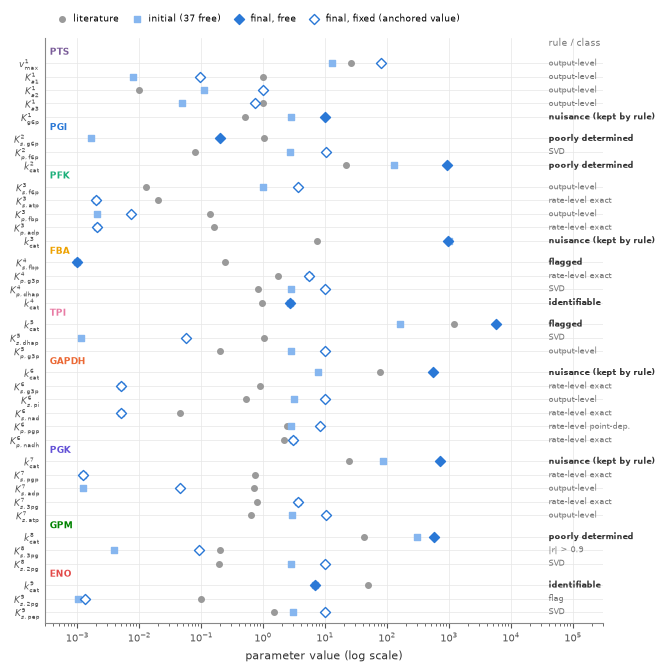

In [6]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

fig, ax = plt.subplots(figsize=(7.2, 7.6))
for yy in y:
    ax.axhline(yy, color=S.GRID, lw=0.5, zorder=0)

ax.scatter(v_lit, y, s=16, marker="o", color=S.STAGE_COLOR["literature"], zorder=2, label="literature")
ax.scatter(v_0, y, s=16, marker="s", color=S.STAGE_COLOR["stage0"], zorder=3, label="initial (37 free)")
ax.scatter(v_f[is_free], y[is_free], s=26, marker="D", color=S.STAGE_COLOR["final"], zorder=4, label="final, free")
ax.scatter(v_f[~is_free], y[~is_free], s=26, marker="D", facecolors="white", edgecolors=S.STAGE_COLOR["final"], linewidths=1.0, zorder=4, label="final, fixed (anchored value)")
ax.set_xscale("log")
ax.set_xlim(3e-4, 3e5)
ax.set_yticks(y)
ax.set_yticklabels([S.label(p) for p in params], fontsize=6.6)
ax.set_ylim(y.max() + 0.8, -1.9)
ax.tick_params(axis="y", length=0)
for yy, txt, fr in zip(y, rule_txt, is_free):
    ax.text(4e4, yy, txt, fontsize=6.0, va="center", ha="left", color=S.INK if fr else S.MUTED, fontweight="bold" if fr else "normal")

for r in range(1, 10):
    ax.text(3.6e-4, rxn_top[r - 1] - 0.8, S.REACTIONS[r - 1], fontsize=6.6, va="center", ha="left", color=S.REACTION_COLOR[r - 1], fontweight="bold")

ax.text(4e4, -1.5, "rule / class", fontsize=6.4, ha="left", va="center", color=S.MUTED)
ax.set_xlabel("parameter value (log scale)")
ax.grid(axis="x", color=S.GRID, lw=0.5)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=4, frameon=False, fontsize=6.4, handletextpad=0.3, columnspacing=1.0)

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "figS_parameter_evolution.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "figS_parameter_evolution.pdf"), bbox_inches="tight")

plt.show()

## Fig. S8: bootstrap distributions of the free parameters

One panel per free parameter, $x = \log_{10}(\theta^* / \hat\theta)$ over the converged resamples, the estimate (black line) and the bias-corrected 95% interval (shaded); colour = class. Parameters the data cannot move return their warm start, so a narrow distribution there is not information.

In [7]:
if len(FREE) != 11:
    raise ValueError("figS_bootstrap_all and figS_profiles_all are laid out for 11 free parameters, this run has %d: %s" % (len(FREE), FREE))

boot = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
boot = boot[boot["converged"]].reset_index(drop=True)
B = {}
for p in FREE:
    tb = boot[p].to_numpy(float)
    th = float(thf[p])
    z0 = scipy.stats.norm.ppf(np.clip(np.mean(tb < th), 1e-12, 1 - 1e-12))
    a1 = scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.025))
    a2 = scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.975))
    lo, hi = np.percentile(tb, 100 * a1), np.percentile(tb, 100 * a2)
    d = np.log10(tb / th)
    q_lo, q_hi = min(np.percentile(d, 0.5), 0.0), max(np.percentile(d, 99.5), 0.0)
    pad = max(0.05 * (q_hi - q_lo), 1e-4)
    q_lo, q_hi = q_lo - pad, q_hi + pad
    bins = np.linspace(q_lo, q_hi, 40)
    B[p] = {"d": d, "lo": np.log10(lo / th), "hi": np.log10(hi / th), "bins": bins, "xlim": (q_lo, q_hi),
            "out": float(np.mean((d < q_lo) | (d > q_hi))), "color": S.CLASS_COLOR[CLASS_OF[p]]}

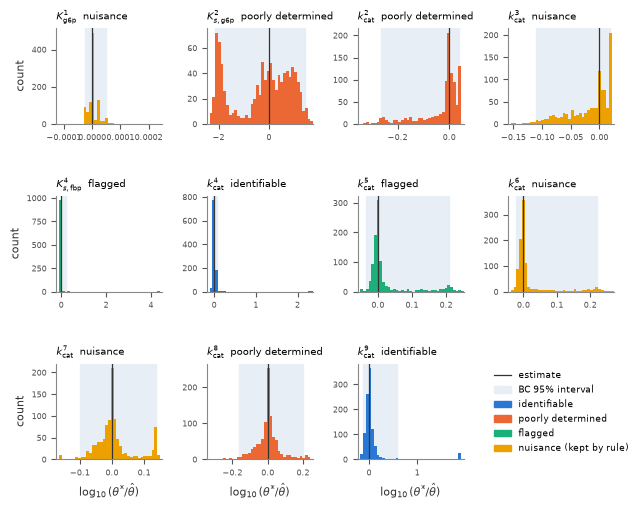

In [8]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

fig, axes = plt.subplots(3, 4, figsize=(7.2, 5.6))
plt.subplots_adjust(wspace=0.42, hspace=0.75)
ax_a, ax_b, ax_c, ax_d = axes[0]
ax_e, ax_f, ax_g, ax_h = axes[1]
ax_i, ax_j, ax_k, ax_leg = axes[2]

# ---- panel 1: FREE[0] ----
ax_a.axvspan(B[FREE[0]]["lo"], B[FREE[0]]["hi"], color="#e8eef5", zorder=0)
ax_a.hist(B[FREE[0]]["d"], bins=B[FREE[0]]["bins"], color=B[FREE[0]]["color"], zorder=2)
ax_a.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_a.set_xlim(*B[FREE[0]]["xlim"])
ax_a.set_title(S.label(FREE[0]) + "  " + CLASS_OF[FREE[0]].split(" (")[0], fontsize=7.2)
ax_a.tick_params(axis="x", labelsize=6.0)
ax_a.tick_params(axis="y", labelsize=6.0)

# ---- panel 2: FREE[1] ----
ax_b.axvspan(B[FREE[1]]["lo"], B[FREE[1]]["hi"], color="#e8eef5", zorder=0)
ax_b.hist(B[FREE[1]]["d"], bins=B[FREE[1]]["bins"], color=B[FREE[1]]["color"], zorder=2)
ax_b.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_b.set_xlim(*B[FREE[1]]["xlim"])
ax_b.set_title(S.label(FREE[1]) + "  " + CLASS_OF[FREE[1]].split(" (")[0], fontsize=7.2)
ax_b.tick_params(axis="x", labelsize=6.0)
ax_b.tick_params(axis="y", labelsize=6.0)

# ---- panel 3: FREE[2] ----
ax_c.axvspan(B[FREE[2]]["lo"], B[FREE[2]]["hi"], color="#e8eef5", zorder=0)
ax_c.hist(B[FREE[2]]["d"], bins=B[FREE[2]]["bins"], color=B[FREE[2]]["color"], zorder=2)
ax_c.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_c.set_xlim(*B[FREE[2]]["xlim"])
ax_c.set_title(S.label(FREE[2]) + "  " + CLASS_OF[FREE[2]].split(" (")[0], fontsize=7.2)
ax_c.tick_params(axis="x", labelsize=6.0)
ax_c.tick_params(axis="y", labelsize=6.0)

# ---- panel 4: FREE[3] ----
ax_d.axvspan(B[FREE[3]]["lo"], B[FREE[3]]["hi"], color="#e8eef5", zorder=0)
ax_d.hist(B[FREE[3]]["d"], bins=B[FREE[3]]["bins"], color=B[FREE[3]]["color"], zorder=2)
ax_d.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_d.set_xlim(*B[FREE[3]]["xlim"])
ax_d.set_title(S.label(FREE[3]) + "  " + CLASS_OF[FREE[3]].split(" (")[0], fontsize=7.2)
ax_d.tick_params(axis="x", labelsize=6.0)
ax_d.tick_params(axis="y", labelsize=6.0)

# ---- panel 5: FREE[4] ----
ax_e.axvspan(B[FREE[4]]["lo"], B[FREE[4]]["hi"], color="#e8eef5", zorder=0)
ax_e.hist(B[FREE[4]]["d"], bins=B[FREE[4]]["bins"], color=B[FREE[4]]["color"], zorder=2)
ax_e.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_e.set_xlim(*B[FREE[4]]["xlim"])
ax_e.set_title(S.label(FREE[4]) + "  " + CLASS_OF[FREE[4]].split(" (")[0], fontsize=7.2)
ax_e.tick_params(axis="x", labelsize=6.0)
ax_e.tick_params(axis="y", labelsize=6.0)

# ---- panel 6: FREE[5] ----
ax_f.axvspan(B[FREE[5]]["lo"], B[FREE[5]]["hi"], color="#e8eef5", zorder=0)
ax_f.hist(B[FREE[5]]["d"], bins=B[FREE[5]]["bins"], color=B[FREE[5]]["color"], zorder=2)
ax_f.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_f.set_xlim(*B[FREE[5]]["xlim"])
ax_f.set_title(S.label(FREE[5]) + "  " + CLASS_OF[FREE[5]].split(" (")[0], fontsize=7.2)
ax_f.tick_params(axis="x", labelsize=6.0)
ax_f.tick_params(axis="y", labelsize=6.0)

# ---- panel 7: FREE[6] ----
ax_g.axvspan(B[FREE[6]]["lo"], B[FREE[6]]["hi"], color="#e8eef5", zorder=0)
ax_g.hist(B[FREE[6]]["d"], bins=B[FREE[6]]["bins"], color=B[FREE[6]]["color"], zorder=2)
ax_g.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_g.set_xlim(*B[FREE[6]]["xlim"])
ax_g.set_title(S.label(FREE[6]) + "  " + CLASS_OF[FREE[6]].split(" (")[0], fontsize=7.2)
ax_g.tick_params(axis="x", labelsize=6.0)
ax_g.tick_params(axis="y", labelsize=6.0)

# ---- panel 8: FREE[7] ----
ax_h.axvspan(B[FREE[7]]["lo"], B[FREE[7]]["hi"], color="#e8eef5", zorder=0)
ax_h.hist(B[FREE[7]]["d"], bins=B[FREE[7]]["bins"], color=B[FREE[7]]["color"], zorder=2)
ax_h.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_h.set_xlim(*B[FREE[7]]["xlim"])
ax_h.set_title(S.label(FREE[7]) + "  " + CLASS_OF[FREE[7]].split(" (")[0], fontsize=7.2)
ax_h.tick_params(axis="x", labelsize=6.0)
ax_h.tick_params(axis="y", labelsize=6.0)

# ---- panel 9: FREE[8] ----
ax_i.axvspan(B[FREE[8]]["lo"], B[FREE[8]]["hi"], color="#e8eef5", zorder=0)
ax_i.hist(B[FREE[8]]["d"], bins=B[FREE[8]]["bins"], color=B[FREE[8]]["color"], zorder=2)
ax_i.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_i.set_xlim(*B[FREE[8]]["xlim"])
ax_i.set_title(S.label(FREE[8]) + "  " + CLASS_OF[FREE[8]].split(" (")[0], fontsize=7.2)
ax_i.tick_params(axis="x", labelsize=6.0)
ax_i.tick_params(axis="y", labelsize=6.0)

# ---- panel 10: FREE[9] ----
ax_j.axvspan(B[FREE[9]]["lo"], B[FREE[9]]["hi"], color="#e8eef5", zorder=0)
ax_j.hist(B[FREE[9]]["d"], bins=B[FREE[9]]["bins"], color=B[FREE[9]]["color"], zorder=2)
ax_j.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_j.set_xlim(*B[FREE[9]]["xlim"])
ax_j.set_title(S.label(FREE[9]) + "  " + CLASS_OF[FREE[9]].split(" (")[0], fontsize=7.2)
ax_j.tick_params(axis="x", labelsize=6.0)
ax_j.tick_params(axis="y", labelsize=6.0)

# ---- panel 11: FREE[10] ----
ax_k.axvspan(B[FREE[10]]["lo"], B[FREE[10]]["hi"], color="#e8eef5", zorder=0)
ax_k.hist(B[FREE[10]]["d"], bins=B[FREE[10]]["bins"], color=B[FREE[10]]["color"], zorder=2)
ax_k.axvline(0.0, color=S.INK, lw=0.9, zorder=3)
ax_k.set_xlim(*B[FREE[10]]["xlim"])
ax_k.set_title(S.label(FREE[10]) + "  " + CLASS_OF[FREE[10]].split(" (")[0], fontsize=7.2)
ax_k.tick_params(axis="x", labelsize=6.0)
ax_k.tick_params(axis="y", labelsize=6.0)

# ---- legend cell ----
ax_leg.axis("off")
ax_leg.legend(handles=[Line2D([0], [0], color=S.INK, lw=0.9, label="estimate"),
                       Patch(color="#e8eef5", label="BC 95% interval"),
                       Patch(color=S.CLASS_COLOR["identifiable"], label="identifiable"),
                       Patch(color=S.CLASS_COLOR["poorly determined"], label="poorly determined"),
                       Patch(color=S.CLASS_COLOR["flagged"], label="flagged"),
                       Patch(color=S.CLASS_COLOR["nuisance (kept by rule)"], label="nuisance (kept by rule)")],
              loc="center", frameon=False, fontsize=6.4)
ax_a.set_ylabel("count")
ax_e.set_ylabel("count")
ax_i.set_ylabel("count")
ax_i.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")
ax_j.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")
ax_k.set_xlabel("$\\log_{10}(\\theta^{*} / \\hat{\\theta})$")

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "figS_bootstrap_all.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "figS_bootstrap_all.pdf"), bbox_inches="tight")

plt.show()

## Fig. S9: profile likelihoods of the free parameters

Re-optimised profiles ($\pm 0.5$ decades), objective minus the lowest profile value, with the 95% threshold $\chi^2_{0.95,1}/(2N)$; panels share both axes and show the profile class in the title. Profile re-fits start without duals and sit slightly above the estimate.

In [9]:
prof = pd.read_csv(path("profiles", "profiles_all.csv"))
thr = json.load(open(path("profiles", "profile_thresholds.json")))
obj_hat = float(thr["obj_hat"])
lr = float(thr["lr_threshold_0.95"])
P = {}
for p in FREE:
    d = prof[prof["param"] == p].sort_values("log10_offset")
    P[p] = {"x": d["log10_offset"].to_numpy(float), "y": d["obj"].to_numpy(float) - obj_hat,
            "cls": profile_summary.loc[p, "class_lr"].replace("_", "-"), "color": S.CLASS_COLOR[CLASS_OF[p]]}

YMAX = 0.4

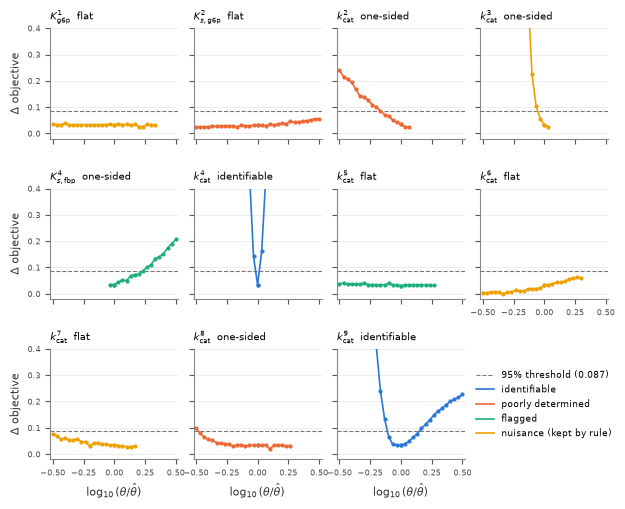

In [10]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

fig, axes = plt.subplots(3, 4, figsize=(7.2, 5.6), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0.45)
ax_a, ax_b, ax_c, ax_d = axes[0]
ax_e, ax_f, ax_g, ax_h = axes[1]
ax_i, ax_j, ax_k, ax_leg = axes[2]

# ---- panel 1: FREE[0] ----
ax_a.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_a.plot(P[FREE[0]]["x"], np.clip(P[FREE[0]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[0]]["color"])
ax_a.set_ylim(-0.02, YMAX)
ax_a.set_xlim(-0.52, 0.52)
ax_a.set_title(S.label(FREE[0]) + "  " + P[FREE[0]]["cls"], fontsize=7.2)
ax_a.grid(axis="y", color=S.GRID, lw=0.5)
ax_a.tick_params(labelsize=6.0)

# ---- panel 2: FREE[1] ----
ax_b.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_b.plot(P[FREE[1]]["x"], np.clip(P[FREE[1]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[1]]["color"])
ax_b.set_ylim(-0.02, YMAX)
ax_b.set_xlim(-0.52, 0.52)
ax_b.set_title(S.label(FREE[1]) + "  " + P[FREE[1]]["cls"], fontsize=7.2)
ax_b.grid(axis="y", color=S.GRID, lw=0.5)
ax_b.tick_params(labelsize=6.0)

# ---- panel 3: FREE[2] ----
ax_c.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_c.plot(P[FREE[2]]["x"], np.clip(P[FREE[2]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[2]]["color"])
ax_c.set_ylim(-0.02, YMAX)
ax_c.set_xlim(-0.52, 0.52)
ax_c.set_title(S.label(FREE[2]) + "  " + P[FREE[2]]["cls"], fontsize=7.2)
ax_c.grid(axis="y", color=S.GRID, lw=0.5)
ax_c.tick_params(labelsize=6.0)

# ---- panel 4: FREE[3] ----
ax_d.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_d.plot(P[FREE[3]]["x"], np.clip(P[FREE[3]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[3]]["color"])
ax_d.set_ylim(-0.02, YMAX)
ax_d.set_xlim(-0.52, 0.52)
ax_d.set_title(S.label(FREE[3]) + "  " + P[FREE[3]]["cls"], fontsize=7.2)
ax_d.grid(axis="y", color=S.GRID, lw=0.5)
ax_d.tick_params(labelsize=6.0)

# ---- panel 5: FREE[4] ----
ax_e.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_e.plot(P[FREE[4]]["x"], np.clip(P[FREE[4]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[4]]["color"])
ax_e.set_ylim(-0.02, YMAX)
ax_e.set_xlim(-0.52, 0.52)
ax_e.set_title(S.label(FREE[4]) + "  " + P[FREE[4]]["cls"], fontsize=7.2)
ax_e.grid(axis="y", color=S.GRID, lw=0.5)
ax_e.tick_params(labelsize=6.0)

# ---- panel 6: FREE[5] ----
ax_f.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_f.plot(P[FREE[5]]["x"], np.clip(P[FREE[5]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[5]]["color"])
ax_f.set_ylim(-0.02, YMAX)
ax_f.set_xlim(-0.52, 0.52)
ax_f.set_title(S.label(FREE[5]) + "  " + P[FREE[5]]["cls"], fontsize=7.2)
ax_f.grid(axis="y", color=S.GRID, lw=0.5)
ax_f.tick_params(labelsize=6.0)

# ---- panel 7: FREE[6] ----
ax_g.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_g.plot(P[FREE[6]]["x"], np.clip(P[FREE[6]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[6]]["color"])
ax_g.set_ylim(-0.02, YMAX)
ax_g.set_xlim(-0.52, 0.52)
ax_g.set_title(S.label(FREE[6]) + "  " + P[FREE[6]]["cls"], fontsize=7.2)
ax_g.grid(axis="y", color=S.GRID, lw=0.5)
ax_g.tick_params(labelsize=6.0)

# ---- panel 8: FREE[7] ----
ax_h.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_h.plot(P[FREE[7]]["x"], np.clip(P[FREE[7]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[7]]["color"])
ax_h.set_ylim(-0.02, YMAX)
ax_h.set_xlim(-0.52, 0.52)
ax_h.set_title(S.label(FREE[7]) + "  " + P[FREE[7]]["cls"], fontsize=7.2)
ax_h.grid(axis="y", color=S.GRID, lw=0.5)
ax_h.tick_params(labelsize=6.0)

# ---- panel 9: FREE[8] ----
ax_i.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_i.plot(P[FREE[8]]["x"], np.clip(P[FREE[8]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[8]]["color"])
ax_i.set_ylim(-0.02, YMAX)
ax_i.set_xlim(-0.52, 0.52)
ax_i.set_title(S.label(FREE[8]) + "  " + P[FREE[8]]["cls"], fontsize=7.2)
ax_i.grid(axis="y", color=S.GRID, lw=0.5)
ax_i.tick_params(labelsize=6.0)

# ---- panel 10: FREE[9] ----
ax_j.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_j.plot(P[FREE[9]]["x"], np.clip(P[FREE[9]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[9]]["color"])
ax_j.set_ylim(-0.02, YMAX)
ax_j.set_xlim(-0.52, 0.52)
ax_j.set_title(S.label(FREE[9]) + "  " + P[FREE[9]]["cls"], fontsize=7.2)
ax_j.grid(axis="y", color=S.GRID, lw=0.5)
ax_j.tick_params(labelsize=6.0)

# ---- panel 11: FREE[10] ----
ax_k.axhline(lr, color=S.MUTED, lw=0.8, ls="--")
ax_k.plot(P[FREE[10]]["x"], np.clip(P[FREE[10]]["y"], None, YMAX * 1.5), "-o", ms=2.0, lw=1.2, color=P[FREE[10]]["color"])
ax_k.set_ylim(-0.02, YMAX)
ax_k.set_xlim(-0.52, 0.52)
ax_k.set_title(S.label(FREE[10]) + "  " + P[FREE[10]]["cls"], fontsize=7.2)
ax_k.grid(axis="y", color=S.GRID, lw=0.5)
ax_k.tick_params(labelsize=6.0)

# ---- legend cell ----
ax_leg.axis("off")
ax_leg.legend(handles=[Line2D([0], [0], color=S.MUTED, lw=0.8, ls="--", label="95%% threshold (%.3f)" % lr),
                       Line2D([0], [0], color=S.CLASS_COLOR["identifiable"], lw=1.2, label="identifiable"),
                       Line2D([0], [0], color=S.CLASS_COLOR["poorly determined"], lw=1.2, label="poorly determined"),
                       Line2D([0], [0], color=S.CLASS_COLOR["flagged"], lw=1.2, label="flagged"),
                       Line2D([0], [0], color=S.CLASS_COLOR["nuisance (kept by rule)"], lw=1.2, label="nuisance (kept by rule)")],
              loc="center", frameon=False, fontsize=6.4)
ax_a.set_ylabel("$\\Delta$ objective")
ax_e.set_ylabel("$\\Delta$ objective")
ax_i.set_ylabel("$\\Delta$ objective")
ax_i.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_j.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_k.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_h.tick_params(labelbottom=True)

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "figS_profiles_all.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "figS_profiles_all.pdf"), bbox_inches="tight")

plt.show()